In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [5]:
df = pd.read_csv("CC GENERAL.csv")

print(df.head())

  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  
0                    0.000000                          0.083333  
1                    0.000000         

In [6]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (8950, 10)

Column names:
['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY']

Data types:
CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
dtype: object


In [7]:
for column in df.columns:
    print(column)

CUST_ID
BALANCE
BALANCE_FREQUENCY
PURCHASES
ONEOFF_PURCHASES
INSTALLMENTS_PURCHASES
CASH_ADVANCE
PURCHASES_FREQUENCY
ONEOFF_PURCHASES_FREQUENCY
PURCHASES_INSTALLMENTS_FREQUENCY


In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df.describe())

Missing values:
CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
dtype: int64

Summary statistics:
            BALANCE  BALANCE_FREQUENCY     PURCHASES  ONEOFF_PURCHASES  \
count   8950.000000        8950.000000   8950.000000       8950.000000   
mean    1564.474828           0.877271   1003.204834        592.437371   
std     2081.531879           0.236904   2136.634782       1659.887917   
min        0.000000           0.000000      0.000000          0.000000   
25%      128.281915           0.888889     39.635000          0.000000   
50%      873.385231           1.000000    361.280000         38.000000   
75%     2054.140036           1.000000   1110.130000

In [9]:
X = df[["BALANCE", "PURCHASES"]].copy()

print(X.head())

       BALANCE  PURCHASES
0    40.900749      95.40
1  3202.467416       0.00
2  2495.148862     773.17
3  1666.670542    1499.00
4   817.714335      16.00


In [10]:
balance_limit = X["BALANCE"].quantile(0.70)
purchase_limit = X["PURCHASES"].quantile(0.70)

y = (
    (X["BALANCE"] >= balance_limit) &
    (X["PURCHASES"] >= purchase_limit)
).astype(int)

print("Balance threshold:", balance_limit)
print("Purchase threshold:", purchase_limit)

print("\nCustomer class counts:")
print(y.value_counts().sort_index())

Balance threshold: 1698.5888545999994
Purchase threshold: 894.3159999999999

Customer class counts:
0    7995
1     955
Name: count, dtype: int64


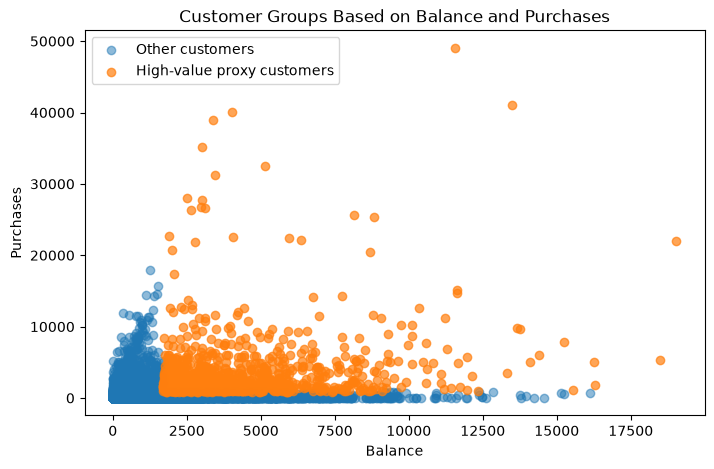

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X.loc[y == 0, "BALANCE"],
    X.loc[y == 0, "PURCHASES"],
    label="Other customers",
    alpha=0.5
)

plt.scatter(
    X.loc[y == 1, "BALANCE"],
    X.loc[y == 1, "PURCHASES"],
    label="High-value proxy customers",
    alpha=0.7
)

plt.xlabel("Balance")
plt.ylabel("Purchases")
plt.title("Customer Groups Based on Balance and Purchases")
plt.legend()
plt.show()

In [12]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

svm_model = SVC(kernel="linear", C=1)

svm_model.fit(X_scaled, y)

print("Linear SVM training completed.")
print("Training accuracy:", svm_model.score(X_scaled, y))

Linear SVM training completed.
Training accuracy: 0.9121787709497207


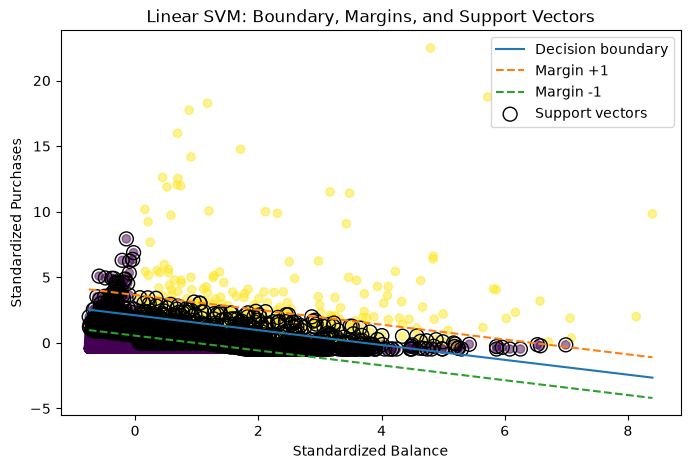

In [13]:
w = svm_model.coef_[0]
b = svm_model.intercept_[0]

x_values = np.linspace(
    X_scaled[:, 0].min(),
    X_scaled[:, 0].max(),
    200
)

decision_line = -(w[0] * x_values + b) / w[1]
upper_margin = (1 - (w[0] * x_values + b)) / w[1]
lower_margin = (-1 - (w[0] * x_values + b)) / w[1]

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    alpha=0.5
)

plt.plot(x_values, decision_line, label="Decision boundary")
plt.plot(x_values, upper_margin, "--", label="Margin +1")
plt.plot(x_values, lower_margin, "--", label="Margin -1")

support_vectors = svm_model.support_vectors_

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    label="Support vectors"
)

plt.xlabel("Standardized Balance")
plt.ylabel("Standardized Purchases")
plt.title("Linear SVM: Boundary, Margins, and Support Vectors")
plt.legend()
plt.show()

In [14]:
margin_width = 2 / np.linalg.norm(w)

print("Margin width:", margin_width)

print("\nComparison of different C values:")

for c_value in [0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=c_value)
    model.fit(X_scaled, y)

    print(
        "C =", c_value,
        "| Training accuracy =", round(model.score(X_scaled, y), 4),
        "| Support vectors =", len(model.support_vectors_)
    )

Margin width: 2.7006620022517973

Comparison of different C values:
C = 0.1 | Training accuracy = 0.9122 | Support vectors = 1672
C = 1 | Training accuracy = 0.9122 | Support vectors = 1666
C = 10 | Training accuracy = 0.9122 | Support vectors = 1666
C = 100 | Training accuracy = 0.9122 | Support vectors = 1666


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Remove ID and columns used to create the labels
X = df.drop(columns=["CUST_ID", "BALANCE", "PURCHASES"])

# Split into 60% training, 20% validation, 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (5370, 7)
Validation: (1790, 7)
Testing: (1790, 7)


In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [17]:
best_c = None
best_f1 = -1

for c in [0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=c)
    model.fit(X_train_scaled, y_train)

    val_pred = model.predict(X_val_scaled)
    score = f1_score(y_val, val_pred, zero_division=0)

    print("C:", c, "| Validation F1:", round(score, 4))

    if score > best_f1:
        best_f1 = score
        best_c = c

print("\nBest C:", best_c)
print("Best validation F1:", round(best_f1, 4))

C: 0.1 | Validation F1: 0.1869
C: 1 | Validation F1: 0.1935
C: 10 | Validation F1: 0.1935
C: 100 | Validation F1: 0.1935

Best C: 1
Best validation F1: 0.1935


In [18]:
svm_model = SVC(kernel="linear", C=best_c)
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("Linear SVM Test Results")
print("Accuracy:", round(accuracy_score(y_test, svm_pred), 4))
print("Precision:", round(precision_score(y_test, svm_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, svm_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, svm_pred, zero_division=0), 4))

Linear SVM Test Results
Accuracy: 0.8955
Precision: 0.5667
Recall: 0.089
F1-score: 0.1538


In [19]:
lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Linear SVM": [
        accuracy_score(y_test, svm_pred),
        precision_score(y_test, svm_pred, zero_division=0),
        recall_score(y_test, svm_pred, zero_division=0),
        f1_score(y_test, svm_pred, zero_division=0)
    ],
    "Logistic Regression": [
        accuracy_score(y_test, lr_pred),
        precision_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, lr_pred, zero_division=0)
    ]
})

print(results.round(4))

      Metric  Linear SVM  Logistic Regression
0   Accuracy      0.8955               0.8983
1  Precision      0.5667               0.5495
2     Recall      0.0890               0.2618
3   F1-score      0.1538               0.3546


                            Feature    Weight  Absolute Weight
1                  ONEOFF_PURCHASES  0.415369         0.415369
0                 BALANCE_FREQUENCY  0.386812         0.386812
2            INSTALLMENTS_PURCHASES  0.114515         0.114515
3                      CASH_ADVANCE  0.112656         0.112656
4               PURCHASES_FREQUENCY  0.067842         0.067842
5        ONEOFF_PURCHASES_FREQUENCY -0.056998         0.056998
6  PURCHASES_INSTALLMENTS_FREQUENCY  0.031000         0.031000


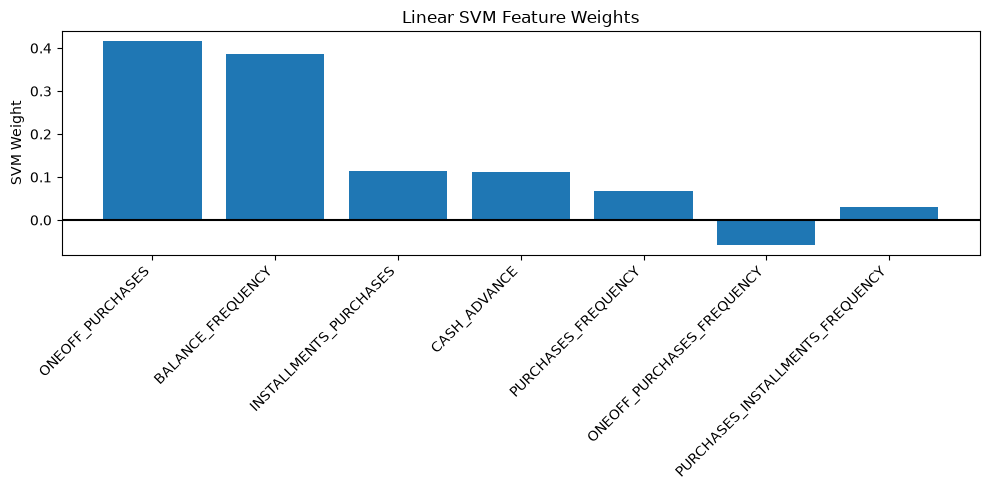

In [20]:
weights = pd.DataFrame({
    "Feature": X.columns,
    "Weight": svm_model.coef_[0]
})

weights["Absolute Weight"] = weights["Weight"].abs()
weights = weights.sort_values("Absolute Weight", ascending=False)

print(weights)

plt.figure(figsize=(10, 5))
plt.bar(weights["Feature"], weights["Weight"])
plt.axhline(0, color="black")
plt.xticks(rotation=45, ha="right")
plt.ylabel("SVM Weight")
plt.title("Linear SVM Feature Weights")
plt.tight_layout()
plt.show()

In [21]:
decision_scores = svm_model.decision_function(X_test_scaled)

borderline = pd.DataFrame({
    "Customer ID": df.loc[X_test.index, "CUST_ID"],
    "Actual Label": y_test,
    "Predicted Label": svm_pred,
    "Decision Score": decision_scores
})

borderline["Absolute Score"] = borderline["Decision Score"].abs()
borderline = borderline.sort_values("Absolute Score")

print("10 customers closest to the decision boundary:")
print(borderline.head(10))

10 customers closest to the decision boundary:
     Customer ID  Actual Label  Predicted Label  Decision Score  \
120       C10125             1                0       -0.008639   
3452      C13549             0                1        0.014109   
3836      C13944             0                0       -0.015023   
3336      C13431             0                1        0.031248   
1193      C11237             0                0       -0.042126   
1150      C11192             0                0       -0.053016   
5421      C15574             0                0       -0.053925   
1218      C11262             0                0       -0.062380   
1053      C11088             0                1        0.079764   
6788      C16976             1                0       -0.080444   

      Absolute Score  
120         0.008639  
3452        0.014109  
3836        0.015023  
3336        0.031248  
1193        0.042126  
1150        0.053016  
5421        0.053925  
1218        0.062380  
1053    

In [22]:
print("1. Explore suitable loyalty offers for customers predicted as high-value.")
print("2. Analyse one-time and installment purchase patterns to understand customer segments.")
print("3. Review borderline customers before making targeted marketing decisions.")

1. Explore suitable loyalty offers for customers predicted as high-value.
2. Analyse one-time and installment purchase patterns to understand customer segments.
3. Review borderline customers before making targeted marketing decisions.
